<a href="https://colab.research.google.com/github/kanselva/MustLearn/blob/master/Train_MNISTData.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np

print(f"TensorFlow Version: {tf.__version__}")


TensorFlow Version: 2.21.0


In [2]:
# Load the dataset (it splits automatically into train and test sets)
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
# Check the shape of the data
print(f"Training data shape: {X_train.shape}")  # Should be (60000, 28, 28)
print(f"Test data shape: {X_test.shape}")      # Should be (10000, 28, 28)


Training data shape: (60000, 28, 28)
Test data shape: (10000, 28, 28)


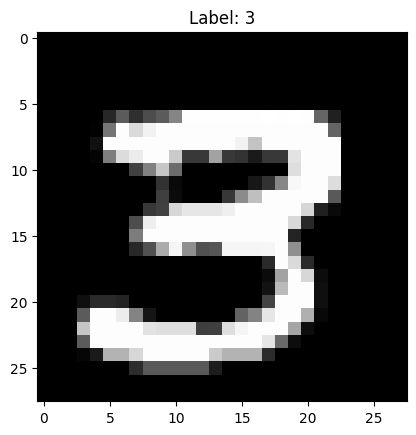

In [4]:
# visualise sample
plt.imshow(X_train[111], cmap='gray')
plt.title(f"Label: {y_train[111]}")
plt.show()

In [5]:
import pandas as pd

# Let's inspect a 10x10 slice of the image at index 111 (centered where features are typically located)
print("Sample pixel values (slice from the center of the 28x28 image):")
# MNIST pixels range from 0 (black/background) to 255 (white/foreground)
display(pd.DataFrame(X_train[111][17:18, 17:18]))

Sample pixel values (slice from the center of the 28x28 image):


,0
0,42


In [6]:
# Normalize pixel values to be between 0 and 1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0
display(pd.DataFrame(X_train[111][17:18, 17:18]))

,0
0,0.164706


In [7]:
model = keras.Sequential([
    # Input Layer: Flattens 28x28 images to a 784 vector
    layers.Flatten(input_shape=(28, 28)),

    # Hidden Layer 1: 128 neurons, ReLU activation
    # ReLU (Rectified Linear Unit) helps the model learn non-linear patterns.
    layers.Dense(128, activation='relu'),

    # Hidden Layer 2 (Optional): 64 neurons, ReLU activation
    layers.Dense(64, activation='relu'),

    # Output Layer: 10 neurons (one for each digit 0-9), Softmax activation
    # Softmax converts the output into a probability distribution totaling 1.0.
    layers.Dense(10, activation='softmax')
])

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


In [9]:

# Train
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)


Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9219 - loss: 0.2698 - val_accuracy: 0.9578 - val_loss: 0.1439
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9652 - loss: 0.1157 - val_accuracy: 0.9680 - val_loss: 0.1084
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9761 - loss: 0.0788 - val_accuracy: 0.9672 - val_loss: 0.1085
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9815 - loss: 0.0582 - val_accuracy: 0.9694 - val_loss: 0.1017
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9850 - loss: 0.0458 - val_accuracy: 0.9697 - val_loss: 0.0961
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9878 - loss: 0.0366 - val_accuracy: 0.9724 - val_loss: 0.0983
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9902 - loss: 0.0304 - val_accuracy: 0.9709 - val_loss: 0.1107
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9919 - loss: 0.0243 - 

In [10]:
# Evaluate
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"\nTest Accuracy: {test_acc * 100:.2f}%")


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9797 - loss: 0.0798

Test Accuracy: 97.97%


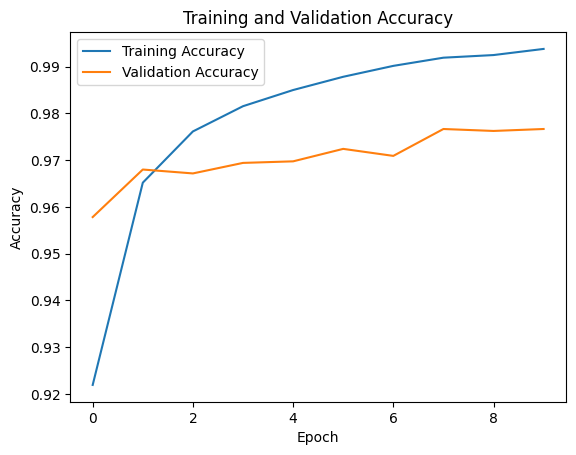

In [11]:
# Plot accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


In [12]:
# Grab the first image from test set
image_index = 0
test_image = X_test[image_index]


In [13]:
# Add a batch dimension (The model expects a batch of images, not just one)
# Shape becomes (1, 28, 28)
input_image = np.expand_dims(test_image, axis=0)

# Predict
predictions = model.predict(input_image)
predicted_label = np.argmax(predictions)

print(f"True Label: {y_test[image_index]}")
print(f"Predicted Label: {predicted_label}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
True Label: 7
Predicted Label: 7


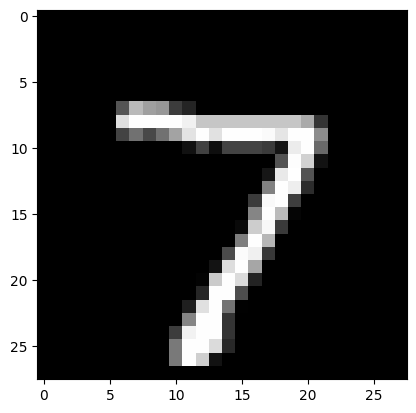

In [14]:
# Show the image
plt.imshow(test_image, cmap='gray')
plt.show()
